# Capstone C8 · A car that drives itself through a city: a mini driving VLA
NVIDIA's **Alpamayo 2 Edge** (S16 notebook 150) is a driving VLA: six cameras, the car's recent motion and a
navigation instruction go in; a chain-of-causation explanation and a 6.4-second trajectory (acceleration and
curvature, from a flow-matching action expert) come out. Here we build the same recipe at laptop scale, end to end:

1. **A city** in MuJoCo: 16 intersections with traffic lights, 24 traffic cars, 40 pedestrians, and sometimes a
   jaywalker who steps out in front of you.
2. **An expert driver** with privileged information (the true positions of everything) records demonstrations.
3. **A mini driving VLA** learns from the front camera, the car's speed and steering, and the instruction
   ("turn left at the next intersection"). It outputs **6 sampled 2-second plans** (flow matching) and a
   **reason** ("red light: stopping at the line"), like Alpamayo's trajectories and reasoning.
4. **Closed-loop evaluation** with Alpamayo's metric: kilometres driven per at-fault incident, per scenario.

Compute: recording + training ≈ 30 min on one big GPU; use the downloaded weights on a laptop.

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt, mujoco
from vlacourse import show_images, show_video, wilson
from vlacourse import showcase as sc
from vlacourse.city import (DriveEnv, collect_drives, record_episode, Lights, REASONS, REASON_TEXT, COMMANDS, PARAPHRASES,
                            G_T, Y_T, AR_T, CYCLE, IDM)
from vlacourse.drive_policy import (DriveData, DriveNet, DrivePolicy, ExpertDriver, train, val_loss, plan_path,
                                    evaluate_driver, summarize, run_episode, SCENARIOS, H)
from vlacourse.drive_film import Film, preview
from vlacourse.lang import TextEmbedder

device = "cuda" if torch.cuda.is_available() else "cpu"
DATA = os.path.join("..", "data", "city_drive_v1")
CKPT = "checkpoints/city_driver.pt"
WORKERS = min(16, os.cpu_count() or 4)            # parallel episodes (each worker: one simulator + one model)
os.makedirs("checkpoints", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("outputs", exist_ok=True)

## 1. The city
Built in code with MjSpec: roads with lane markings and crosswalks, a traffic light for every approach, buildings,
parks and street trees. Static scenery is merged into a dozen meshes (one per material): MuJoCo draws every geom
separately, and 3,000 small geoms render ~7× slower than the same scenery as meshes.
The cars and people are **mocap bodies**: we move them ourselves each step (kinematic traffic, as in most
driving simulators). The ego car's control is what a driving policy outputs: **acceleration** and **curvature**
(1 / turning radius), integrated with the unicycle model at 10 Hz.

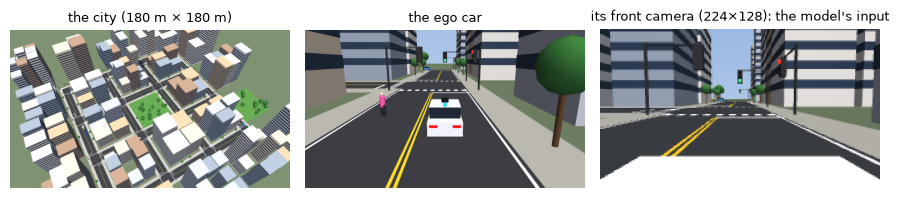

381 geoms, 19 meshes, 66 moving bodies


In [2]:
env = DriveEnv()
obs = env.reset(seed=4, scenario="jaywalker")
for _ in range(60):
    a, _ = env.expert(); obs, _, _ = env.step(a)
r = mujoco.Renderer(env.model, 540, 960); cam = mujoco.MjvCamera()
cam.lookat[:] = [90, 90, 0]; cam.distance, cam.elevation, cam.azimuth = 260, -55, -120
r.update_scene(env.data, cam); overview = r.render()
e = env.ego; cam.lookat[:] = [*e["xy"], 1.2]; cam.distance, cam.elevation, cam.azimuth = 12, -14, np.degrees(e["yaw"])
r.update_scene(env.data, cam); chase = r.render()
show_images([overview, chase, obs["images"]["front"]], ["the city (180 m × 180 m)", "the ego car", "its front camera (224×128): the model's input"], cols=3)
print(f"{env.model.ngeom} geoms, {env.model.nmesh} meshes, {env.model.nmocap} moving bodies")

## 2. The rules of the world
- **Traffic lights:** fixed cycle per intersection with a random phase: green 12 s, yellow 3 s, all-red 2 s per axis.
- **Traffic cars** follow random routes with the **Intelligent Driver Model** (Treiber 2000):
  $a = a_{max}\big[1 - (v/v_0)^4 - (s^*/s)^2\big]$, $s^* = s_0 + vT + \frac{v\,\Delta v}{2\sqrt{a_{max} b}}$, where $s$ is the gap
  to the nearest obstacle in the lane ahead: a car, a pedestrian, or the stop line of a red light.
- **Pedestrians** walk the sidewalks, wait at crosswalks for the walk signal, and don't walk into moving cars.
- **Jaywalker:** in some episodes a pedestrian steps off the kerb mid-block when you're ~3.5 s away.
- **The route:** two intersections, a turn (L / S / R) at each; the instruction always names the next one:

instructions: {'L': 'turn left at the next intersection', 'S': 'go straight at the next intersection', 'R': 'turn right at the next intersection', 'F': 'follow the road'}
paraphrases used in training (left): ['turn left at the next intersection', 'take the next left', 'make a left at the intersection ahead', 'go left at the next junction']


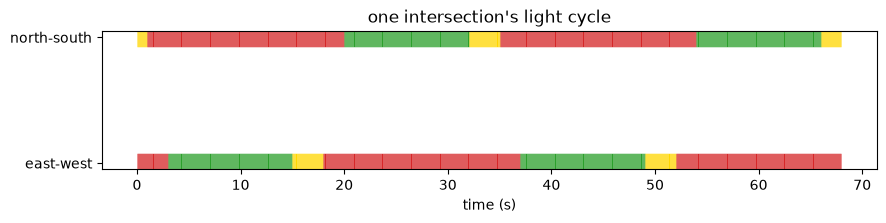

In [3]:
print("instructions:", {k: v for k, v in COMMANDS.items()})
print("paraphrases used in training (left):", PARAPHRASES["L"])
lt = Lights(np.random.default_rng(0)); ts = np.arange(0, 2 * CYCLE, 0.1)
st = {d: [lt.state((1, 1), d, t) for t in ts] for d in (0, 1)}
plt.figure(figsize=(10, 1.8))
for row, d in enumerate((0, 1)):
    for t, s in zip(ts, st[d]):
        plt.plot([t, t + 0.1], [row, row], lw=14, c={"G": "tab:green", "Y": "gold", "R": "tab:red"}[s], solid_capstyle="butt")
plt.yticks([0, 1], ["east-west", "north-south"]); plt.xlabel("time (s)"); plt.title("one intersection's light cycle"); plt.show()

## 3. The expert driver (privileged)
It knows the true position and speed of every car and person, and the state of every light. Lateral control:
**pure pursuit** on the lane centre of the route. Speed: **IDM** against everything in its corridor, a speed limit
from the curvature ahead ($v \le \sqrt{a_{lat}/\kappa}$), red lights, and on left turns it waits for oncoming traffic.
It also reports *which* constraint is active: that's the label for our model's reasoning head.

Five scenario types, 30 episodes each (different seeds = different traffic, routes and light phases):

In [4]:
t0 = time.time()
expert_rec = evaluate_driver("expert", n_per_scenario=30, workers=WORKERS)
rows, km, inc = summarize(expert_rec)
print(f"{'scenario':10s} {'success':>8s}  95% CI        collisions  red lights")
for k, v in rows.items():
    print(f"{k:10s} {v['success']:8.0%}  {v['ci'][0]:.0%}–{v['ci'][1]:.0%}     {v['collision_car'] + v['collision_ped']:5d}      {v['red_light']:5d}")
print(f"expert: {km:.1f} km driven, {inc} incidents  ({time.time() - t0:.0f}s)")

scenario    success  95% CI        collisions  red lights
random          97%  83%–99%         0          0
red            100%  89%–100%         0          0
jaywalker      100%  89%–100%         0          0
left           100%  89%–100%         0          0
right          100%  89%–100%         0          0
expert: 19.8 km driven, 0 incidents  (54s)


## 4. Demonstrations, with noise injection (DART)
A policy trained only on perfect driving never sees what a small mistake looks like, so it can't recover from one
(S06 notebook 60). In 60% of the episodes we add slowly varying noise to the **executed** steering and acceleration,
and record the expert's **clean** action as the label: the data shows how to get back to the lane centre.
Episodes the expert fails are discarded. Frames at 5 Hz (fewer while waiting at a light: they repeat).

In [5]:
if not os.path.exists(f"{DATA}/meta.json"):
    collect_drives(DATA, 800, workers=WORKERS)
meta = json.load(open(f"{DATA}/meta.json"))
print(f"{meta['n_episodes']} episodes kept of {meta['attempts']}, {meta['n_frames']:,} camera frames")

787 episodes kept of 800, 131,361 camera frames


118,754 training samples, 12,607 held out; reasons: cruise 25%, turn 19%, car 11%, red 38%, ped 6%, yield 2%


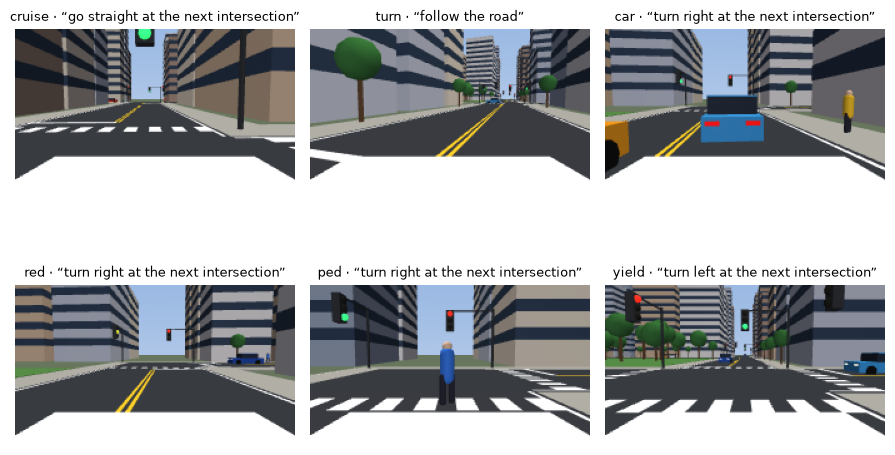

In [6]:
n_val = max(20, meta["n_episodes"] // 10)                       # the last 10% of episodes: never trained on
train_set = DriveData(DATA, episodes=range(0, meta["n_episodes"] - n_val))
val_set = DriveData(DATA, episodes=range(meta["n_episodes"] - n_val, meta["n_episodes"]))
counts = np.bincount(train_set.reason.numpy(), minlength=len(REASONS))
print(f"{len(train_set):,} training samples, {len(val_set):,} held out; reasons: "
      + ", ".join(f"{r} {c / counts.sum():.0%}" for r, c in zip(REASONS, counts)))
rng = np.random.default_rng(0)
pick = [int(rng.choice(np.where(train_set.reason.numpy() == k)[0])) for k in range(len(REASONS)) if counts[k]]
show_images([train_set.img[train_set.idx[i]].numpy() for i in pick],
            [f"{REASONS[int(train_set.reason[i])]} · “{COMMANDS['LSRF'[int(train_set.cmd[i])]]}”" for i in pick], cols=3)

## 5. The model
```
frame now + frame 0.4 s ago ─ ResNet-18 (ImageNet) ─┐
speed, curvature ─────────────────────── MLP ───────┼─ context ─┬─ flow-matching head: 2-s plan of (a, κ), sampled 6×
instruction ─ CLIP text (frozen), 4 paraphrases ────┘           └─ reasoning head: which of 6 reasons applies
```
Two frames, because a single image can't tell a pedestrian standing on the kerb from one walking into the road.
The plan is in the **same action space as Alpamayo's** (acceleration and curvature), integrated by a unicycle model
into the drawn trajectory. Training: flow-matching loss + 0.2 × cross-entropy of the reason, sampled so that
frames of waiting at red lights (the most common situation) don't dominate.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

DriveNet: 14.6M parameters (Alpamayo 2 Edge: ~2,650M), trained on 118,754 samples


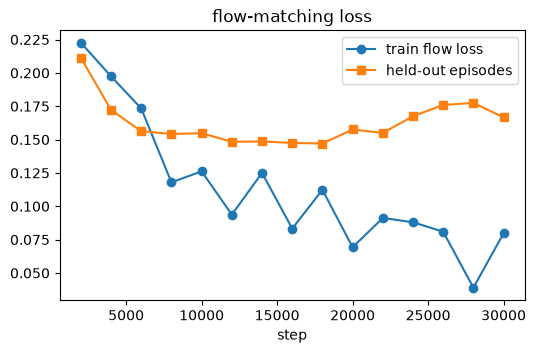

In [7]:
net = DriveNet()
net.set_commands(TextEmbedder(device=device))
print(f"DriveNet: {sum(p.numel() for p in net.parameters()) / 1e6:.1f}M parameters "
      f"(Alpamayo 2 Edge: ~2,650M), trained on {len(train_set):,} samples")
if os.path.exists(CKPT):
    net.load_state_dict(torch.load(CKPT, map_location=device)); net.to(device).eval()
    log = json.load(open("results/C8_train_log.json"))
else:
    train_set.to(device); val_set.to(device)
    t0 = time.time()
    log = train(net, train_set, steps=30_000, bs=128, lr=3e-4, device=device, log_every=2000, val=val_set)
    torch.save(net.state_dict(), CKPT); json.dump(log, open("results/C8_train_log.json", "w"))
    print(f"trained in {(time.time() - t0) / 60:.0f} min")
plt.figure(figsize=(6, 3.5))
plt.plot([r["step"] for r in log], [r["flow"] for r in log], "o-", label="train flow loss")
plt.plot([r["step"] for r in log], [r["val_flow"] for r in log], "s-", label="held-out episodes")
plt.xlabel("step"); plt.legend(); plt.title("flow-matching loss"); plt.show()

## 6. Open loop: plans and reasons on held-out frames
Before driving, check what the model predicts on frames it never saw: six sampled plans (blue) against what the
expert actually did next (black), drawn in the car's frame, and whether the reasoning head names the right reason.

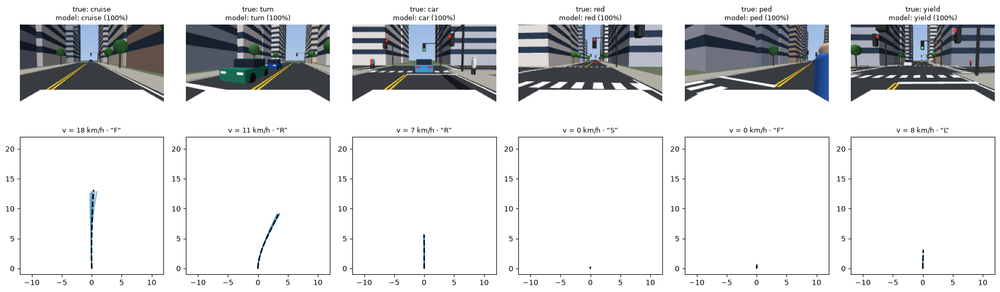

reasoning head on held-out episodes: 96% of frames name the expert's reason


In [8]:
val_set.to(device); net.to(device).eval()
with torch.no_grad():
    vr = val_set.reason.cpu().numpy()
    sel = torch.tensor([int(np.random.default_rng(k).choice(np.where(vr == k)[0])) for k in range(len(REASONS)) if (vr == k).any()],
                       device=device)
    b = dict(img=val_set.img[val_set.idx[sel]], prev=val_set.img[val_set.prev[sel]], speed=val_set.speed[sel],
             kappa=val_set.kappa[sel], cmd=val_set.cmd[sel])
    c = net.context(b["img"], b["prev"], b["speed"], b["kappa"], b["cmd"])
    plans, why = net.sample(c, n=6, generator=torch.Generator(device=device).manual_seed(0))
fig, ax = plt.subplots(2, len(sel), figsize=(3.2 * len(sel), 6))
for j in range(len(sel)):
    ax[0, j].imshow(b["img"][j].cpu().numpy()); ax[0, j].axis("off")
    ax[0, j].set_title(f"true: {REASONS[int(val_set.reason[sel[j]])]}\nmodel: {REASONS[int(why[j].argmax())]} ({why[j].max():.0%})", fontsize=9)
    v = float(b["speed"][j])
    for k in range(6):
        p = plan_path(np.zeros(2), 0.0, v, plans[j, k].float().cpu().numpy())
        ax[1, j].plot(-p[:, 1], p[:, 0], c="tab:blue", alpha=0.6)
    gt = val_set.plan[sel[j]].cpu().numpy() * np.array([3.0, 0.3])
    p = plan_path(np.zeros(2), 0.0, v, gt); ax[1, j].plot(-p[:, 1], p[:, 0], "k--", lw=2)
    ax[1, j].set_aspect("equal"); ax[1, j].set_xlim(-12, 12); ax[1, j].set_ylim(-1, 22)
    ax[1, j].set_title(f"v = {v * 3.6:.0f} km/h · “{'LSRF'[int(b['cmd'][j])]}”", fontsize=9)
plt.tight_layout(); plt.show()

with torch.no_grad():
    correct, total = 0, 0
    for k in range(0, len(val_set), 512):
        ii = torch.arange(k, min(k + 512, len(val_set)), device=device)
        cc = net.context(val_set.img[val_set.idx[ii]], val_set.img[val_set.prev[ii]], val_set.speed[ii], val_set.kappa[ii], val_set.cmd[ii])
        correct += int((net.why(cc).argmax(1) == val_set.reason[ii]).sum()); total += len(ii)
print(f"reasoning head on held-out episodes: {correct / total:.0%} of frames name the expert's reason")
del train_set, val_set; import gc; gc.collect(); torch.cuda.empty_cache()     # free ~13 GB before spawning workers

## 7. Closed loop: the model drives
Same five scenario types and seeds as the expert in section 3. An **incident** is a collision or leaving the road
(Alpamayo's at-fault incident); we also count red-light violations and wrong turns separately.

scenario     model      95% CI  expert   car  ped  off-road  wrong turn  red light  timeout
random         90%  74%–97%      97%     1    0        1           0          0        1
red            93%  79%–98%     100%     0    1        0           1          0        0
jaywalker      90%  74%–97%     100%     2    1        0           0          1        0
left           90%  74%–97%     100%     2    0        0           1          1        0
right          87%  70%–95%     100%     1    2        0           1          0        0
model: 19.1 km, 11 incidents → 1.7 km per incident   (188s)


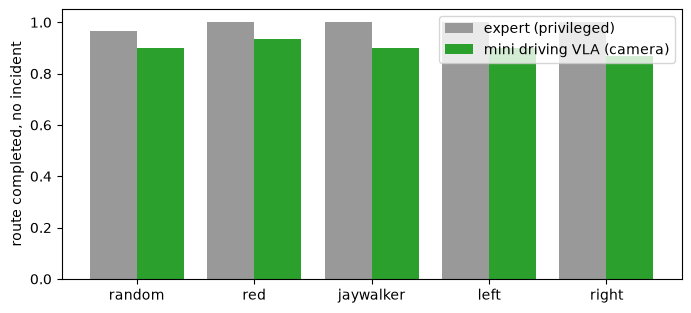

In [9]:
t0 = time.time()
model_rec = evaluate_driver(CKPT, n_per_scenario=30, workers=WORKERS, device=device)
rows_m, km_m, inc_m = summarize(model_rec)
print(f"{'scenario':10s} {'model':>7s} {'95% CI':>11s} {'expert':>7s}   car  ped  off-road  wrong turn  red light  timeout")
for k in rows_m:
    m, x = rows_m[k], rows[k]
    print(f"{k:10s} {m['success']:7.0%} {m['ci'][0]:4.0%}–{m['ci'][1]:<4.0%} {x['success']:7.0%}   {m['collision_car']:3d}  {m['collision_ped']:3d}  "
          f"{m['offroad']:7d}  {m['wrong_way']:10d}  {m['red_light']:9d}  {m['timeout']:7d}")
print(f"model: {km_m:.1f} km, {inc_m} incidents → {km_m / max(inc_m, 1):.1f} km per incident"
      f"{' (no incidents)' if inc_m == 0 else ''}   ({time.time() - t0:.0f}s)")
json.dump(dict(expert=expert_rec, model=model_rec), open("results/C8_closed_loop.json", "w"))
fig, ax = plt.subplots(figsize=(8, 3.5)); xs = np.arange(len(rows_m))
ax.bar(xs - 0.2, [rows[k]["success"] for k in rows_m], 0.4, label="expert (privileged)", color="#999")
ax.bar(xs + 0.2, [rows_m[k]["success"] for k in rows_m], 0.4, label="mini driving VLA (camera)", color="tab:green")
ax.set_xticks(xs, list(rows_m)); ax.set_ylabel("route completed, no incident"); ax.legend(); ax.set_ylim(0, 1.05); plt.show()

## 8. Share-ready video
Four scenarios, each from the chase camera with the six sampled plans on the road, the bird's-eye map, the front
camera, and the model's reasoning as it drives.

In [10]:
pol = DrivePolicy(net, device=device)
film = Film(env, pol)
def first_success(scenario, base):
    ok = [r["seed"] for r in model_rec if r["scenario"] == scenario and r["success"]]
    return ok[0] if ok else base
clips = [("jaywalker", "1 · A pedestrian steps out", "a pedestrian steps out"),
         ("red", "2 · The light turns red", "the light turns red"),
         ("left", "3 · Left turn across oncoming traffic", "unprotected left turn"),
         ("right", "4 · Right turn past a crosswalk", "right turn, crosswalk")]
video = sc.title_card("A car that drives itself, in MuJoCo", "camera + instruction → 6 sampled plans + its reasoning\n"
                      "a mini driving VLA in the spirit of NVIDIA Alpamayo", size=(1080, 1920), n=75)
for scen, title, label in clips:
    seed = first_success(scen, 0)
    frames, info = film.episode(seed, scen, label=label, title=title)
    video += sc.title_card(title, f"scenario: {label}", size=(1080, 1920), n=40) + frames
    print(title, "→", "arrived" if info["success"] else "failed", f"({len(frames) / 30:.0f} s)")
end = sc.title_card("Closed loop, 150 episodes", f"model: {np.mean([r['success'] for r in model_rec]):.0%} routes completed · "
                    f"expert: {np.mean([r['success'] for r in expert_rec]):.0%}\n{km_m:.0f} km driven · {inc_m} incidents", size=(1080, 1920), n=90)
video += end
show_video(preview(video), fps=15, title="C8 city driver preview", width=960)
sc.export(video, "outputs/C8_city_driver.mp4", fps=30)

1 · A pedestrian steps out → arrived (35 s)


2 · The light turns red → arrived (34 s)


3 · Left turn across oncoming traffic → arrived (43 s)


4 · Right turn past a crosswalk → arrived (22 s)


saved outputs/C8_city_driver.mp4  (152.0 MB)


['outputs/C8_city_driver.mp4']

## What this shows, and what it doesn't
- The recipe of a driving VLA (camera + instruction → sampled trajectories + a stated reason) works end to end
  at small scale, and the closed-loop numbers say exactly where it fails.
- The reasoning head is **trained to name the expert's reason**: it is an interpretable output, not proof that the
  plan *follows* from the reason (S16 lecture 150: faithfulness).
- Our world is simple: one city layout, clear weather, kinematic traffic, perfect rendering. Alpamayo is trained on
  115,000 hours of real multi-camera driving.

## Extensions (pick one for your submission)
1. **Ablate the noise injection:** record with `noise_frac=0` and retrain. How many more incidents? (S06 60)
2. **One frame vs two:** drop the earlier frame. Which scenario suffers most?
3. **More cameras:** add side cameras (Alpamayo uses six). Does the unprotected left turn improve?
4. **New layout:** change `city_seed` for testing only. Does the policy generalize to unseen buildings?
5. **Night:** dim the light and turn on the cars' headlights. What breaks first, and does more data fix it?